In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [6]:
file_path = "ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(file_path)

# 1. Display basic info


In [7]:
# 1. Display basic info
print('\n--- Dataset Info ---')
print(df.info())
len(df)


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                    

2111

# 2. Data Cleaning


In [8]:
# 2. Data Cleaning
print('\n--- Cleaning Data ---')
print(f'Initial row count: {len(df)}')
df_example = df.drop_duplicates()
print(f'Row count after cleaning: {len(df_example)}')
#the result show that there are duplicates in the dataset, so we will remove them.
df = df.drop_duplicates()
len(df)



--- Cleaning Data ---
Initial row count: 2111
Row count after cleaning: 2087


2087

# 3. Categorical Encodings


In [9]:
# 3. Categorical Encodings
print('\n--- Encoding Categorical Variables ---')

# Binary columns: map each value explicitly so 1 always means "yes"/"Male"
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
for col in ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']:
    df[col] = df[col].map({'no': 0, 'yes': 1})

# Ordinal mapping for frequency columns
ordinal_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
for col in ['CAEC', 'CALC']:
    df[col] = df[col].map(ordinal_mapping)

# One-Hot Encoding for nominal features (e.g., MTRANS)
df = pd.get_dummies(df, columns=['MTRANS'], drop_first=True, dtype=int)


# Label Encoding for the target variable (NObeyesdad)
# Target classes in order from lightest to heaviest
target_order = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
                'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II',
                'Obesity_Type_III']
df['NObeyesdad'] = df['NObeyesdad'].map({name: i for i, name in enumerate(target_order)})

print(df.head())
print('Missing values after encoding:', df.isnull().sum().sum())


--- Encoding Categorical Variables ---
   Gender   Age  Height  Weight  family_history_with_overweight  FAVC  FCVC  \
0       0  21.0    1.62    64.0                               1     0   2.0   
1       0  21.0    1.52    56.0                               1     0   3.0   
2       1  23.0    1.80    77.0                               1     0   2.0   
3       1  27.0    1.80    87.0                               0     0   3.0   
4       1  22.0    1.78    89.8                               0     0   2.0   

   NCP  CAEC  SMOKE  CH2O  SCC  FAF  TUE  CALC  NObeyesdad  MTRANS_Bike  \
0  3.0     1      0   2.0    0  0.0  1.0     0           1            0   
1  3.0     1      1   3.0    1  3.0  0.0     1           1            0   
2  3.0     1      0   2.0    0  2.0  1.0     2           1            0   
3  3.0     1      0   2.0    0  2.0  0.0     2           2            0   
4  1.0     1      0   2.0    0  0.0  0.0     1           3            0   

   MTRANS_Motorbike  MTRANS_Public

# 4. Feature Scaling 


In [10]:
# 4. Feature Scaling 
#train/test split
print('\n-- Splitting and Scaling ---')

X = df.drop(columns='NObeyesdad')
y = df['NObeyesdad']

#stratified 80/20 data split to keep class proportions in each set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

#Fit scaler on training data only then apply to both sets (scaler now learns average only from train data)
numerical_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print('Train size:', X_train.shape, ' Test size:', X_test.shape)
print('Train class counts:\n', y_train.value_counts().sort_index())


-- Splitting and Scaling ---
Train size: (1669, 19)  Test size: (418, 19)
Train class counts:
 NObeyesdad
0    214
1    225
2    221
3    232
4    281
5    237
6    259
Name: count, dtype: int64


# 5. Exploratory Data Analysis & Visualizations



--- Generating Visualizations ---


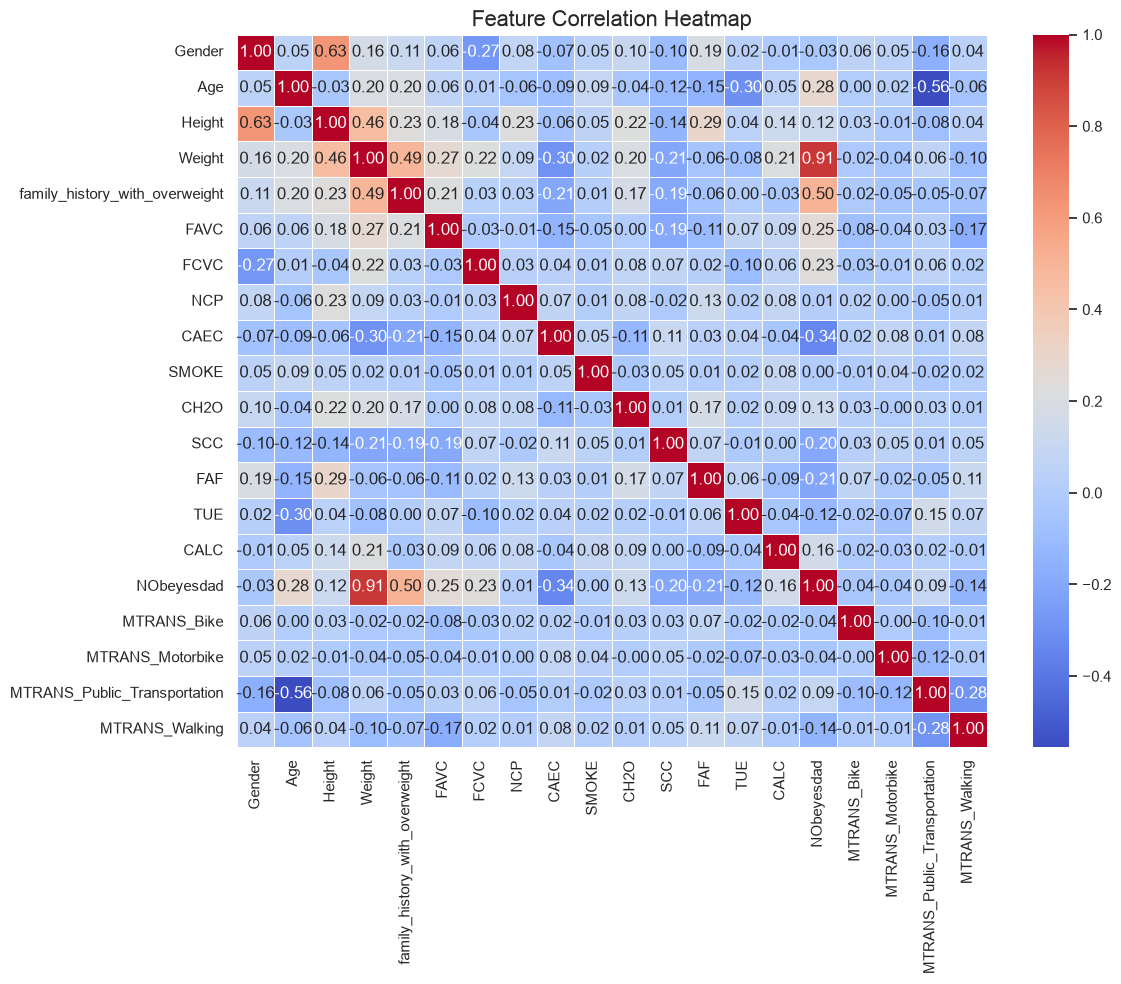

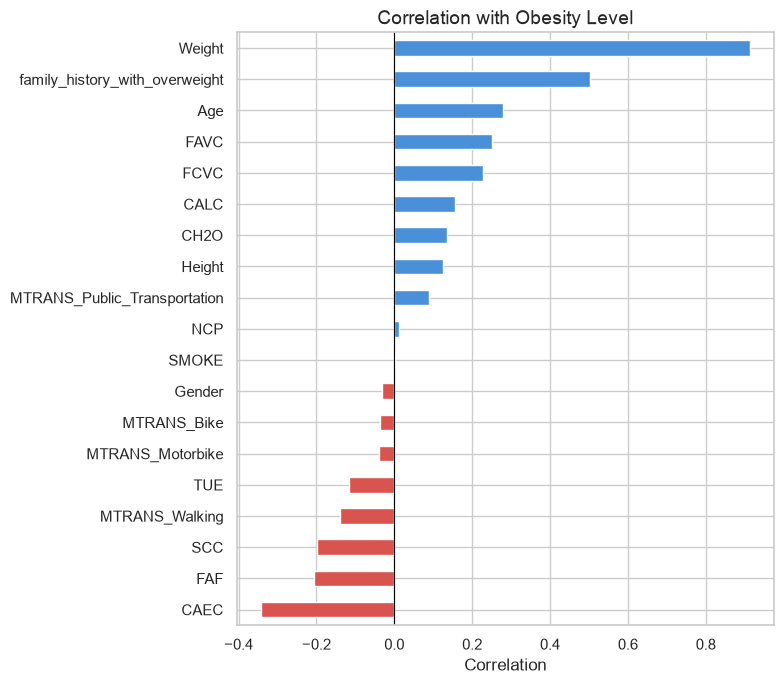

In [11]:
# 5. Exploratory Data Analysis & Visualizations
print('\n--- Generating Visualizations ---')
sns.set_theme(style='whitegrid')

# Figure 1: Correlation Heatmap
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

# Figure 1b: Correlation of each feature with obesity level
target_corr = correlation_matrix['NObeyesdad'].drop('NObeyesdad').sort_values()
plt.figure(figsize=(8, 7))
target_corr.plot(kind='barh', color=['#d9534f' if v < 0 else '#4a90d9' for v in target_corr])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation with Obesity Level', fontsize=14)
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

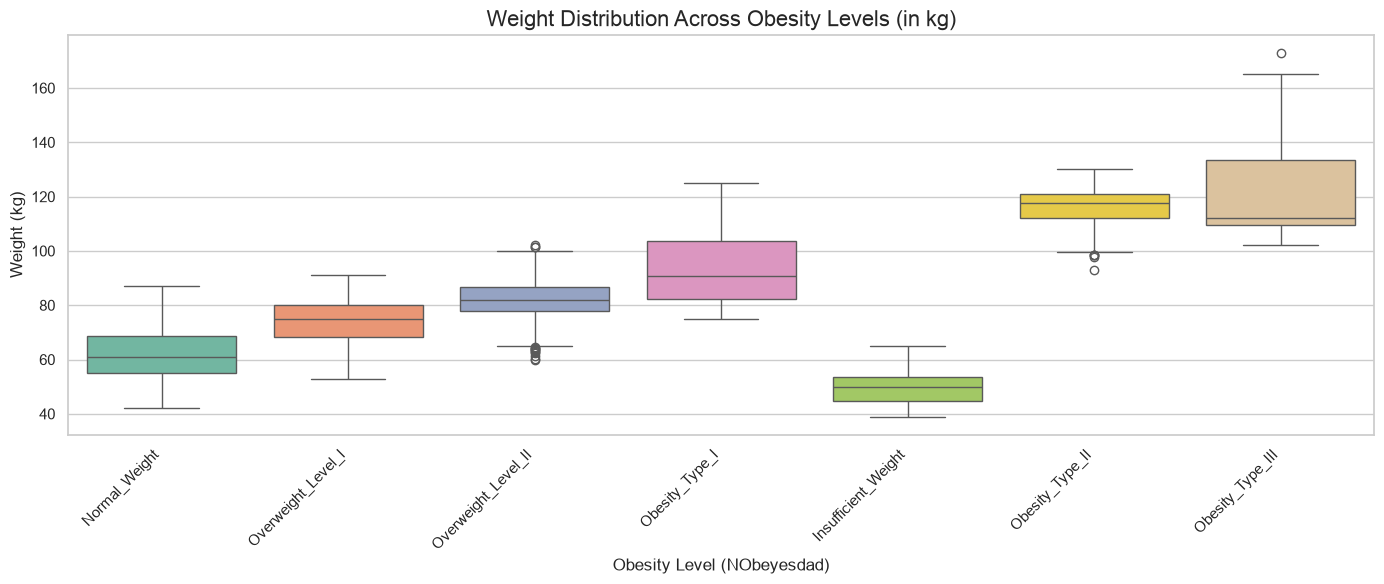

In [12]:
# Figure 2: Weight vs Target Distribution (Boxplot using raw data)
plt.figure(figsize=(14, 6))

df_raw = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

sns.boxplot(
    x='NObeyesdad', y='Weight', data=df_raw, palette='Set2', hue='NObeyesdad', legend=False
)

plt.xticks(rotation=45, ha='right')
plt.title('Weight Distribution Across Obesity Levels (in kg)', fontsize=16)
plt.xlabel('Obesity Level (NObeyesdad)', fontsize=12)
plt.ylabel('Weight (kg)', fontsize=12)
plt.tight_layout()
plt.show()

/var/folders/34/9rf3dhgn53d4rxv8y51t6cq00000gn/T/ipykernel_6211/2925582823.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])


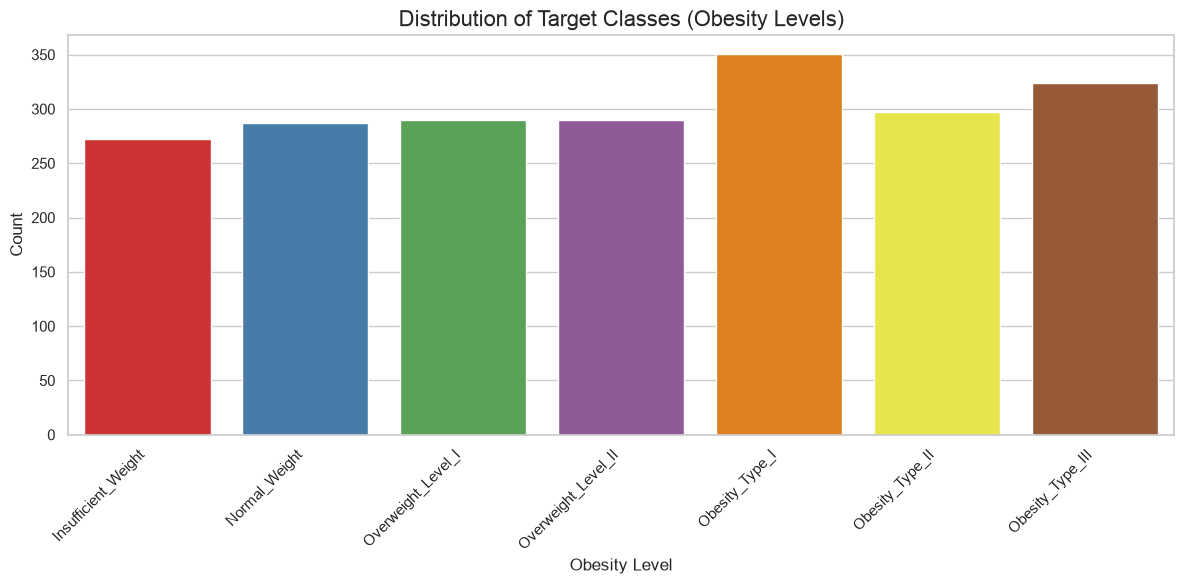

In [13]:
#Figure 3: Distribution of Target Classes (Countplot using raw data)
plt.figure(figsize=(12, 6))
sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Target Classes (Obesity Levels)', fontsize=16)
plt.xlabel('Obesity Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()

plt.show()

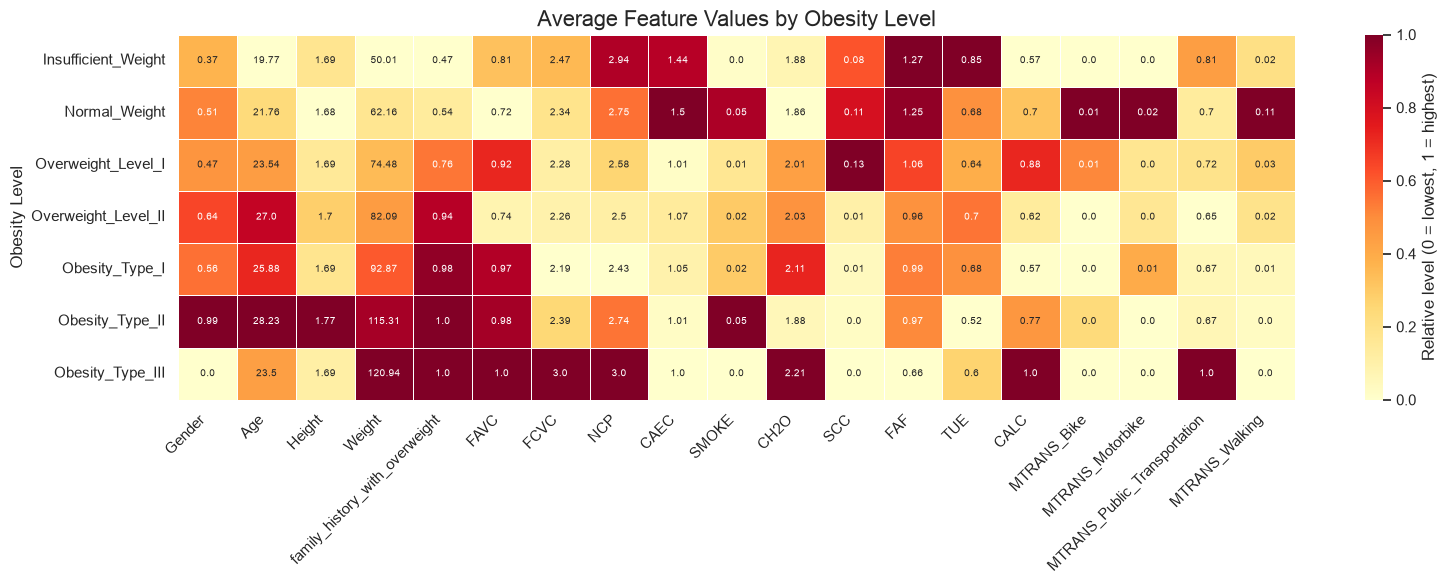

In [14]:
# Figure4: Average feature value for each obesity level (The numbers are the real averages, for example Gender 0.99 means 99% male. The colors show which level has the highest value for that column.)
level_means = df.groupby('NObeyesdad').mean()
level_means.index = target_order          # show names instead of 0-6 for each level

# Scale each column 0-1 so features with different units can share one color scale
level_norm = (level_means - level_means.min()) / (level_means.max() - level_means.min())

plt.figure(figsize=(16, 6))
sns.heatmap(level_norm, annot=level_means.round(2), fmt='', cmap='YlOrRd',
            linewidths=0.5, annot_kws={'size': 7}, cbar_kws={'label': 'Relative level (0 = lowest, 1 = highest)'})
plt.title('Average Feature Values by Obesity Level', fontsize=16)
plt.ylabel('Obesity Level')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

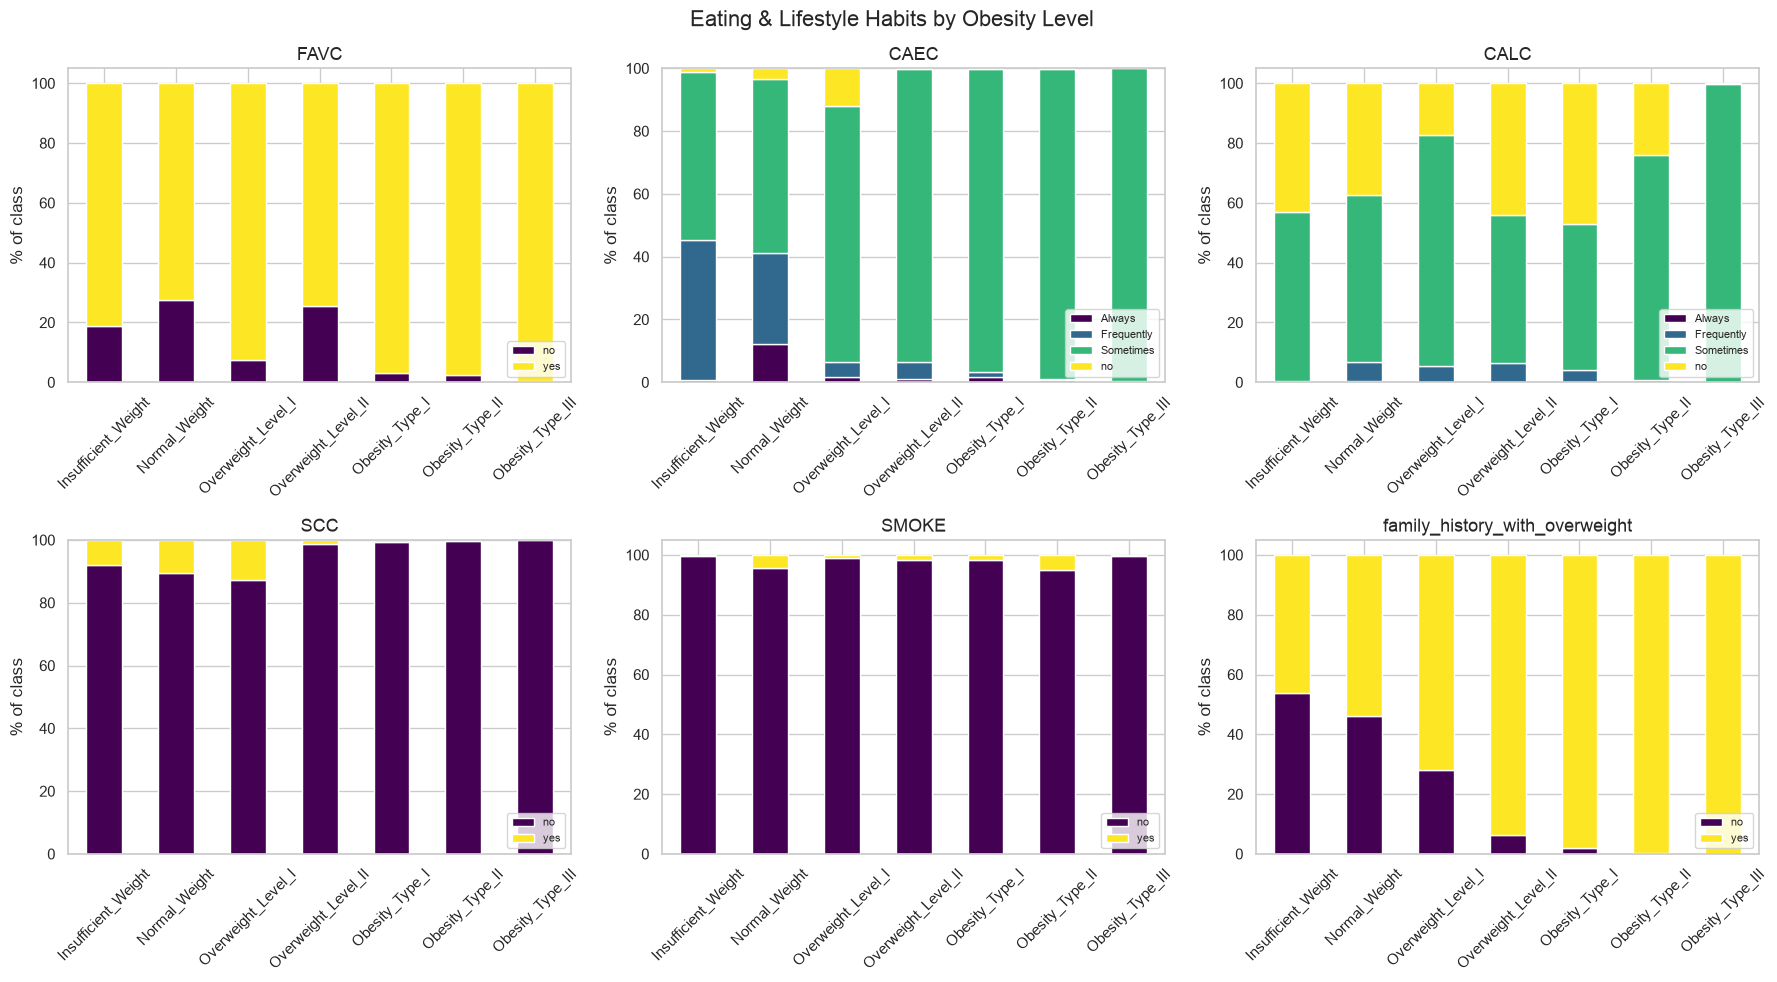

In [15]:
# Figure5: Eating and lifestyle habits across obesity levels
habit_cols = ['FAVC', 'CAEC', 'CALC', 'SCC', 'SMOKE', 'family_history_with_overweight']
order = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
         'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, habit_cols):
    pct = pd.crosstab(df_raw['NObeyesdad'], df_raw[col], normalize='index').loc[order] * 100
    pct.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', legend=True)
    ax.set_title(col, fontsize=13)
    ax.set_xlabel('')
    ax.set_ylabel('% of class')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8, loc='lower right')
plt.suptitle('Eating & Lifestyle Habits by Obesity Level', fontsize=16)
plt.tight_layout()
plt.show()

# 6. Model Selection & Baseline Implementation

In [16]:
# 6. Model Selection & Baseline Implementation
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

## 6.1 Data Split (unscaled copy for pipelines)

In [17]:
# 6.1 Data Split
# X_train/X_test from section 4 were already scaled. For cross-validation the scaler must be
# fit inside each fold, so we redo the same stratified split on the unscaled features.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Same random_state and stratify -> identical rows as the split in section 4
assert X_train_raw.index.equals(X_train.index) and X_test_raw.index.equals(X_test.index)

print('Train size:', X_train_raw.shape, ' Test size:', X_test_raw.shape)
print('Class proportions (train vs test):')
print(pd.DataFrame({'train': y_train.value_counts(normalize=True).sort_index(),
                    'test': y_test.value_counts(normalize=True).sort_index()},
                   ).set_axis(target_order).round(3))

Train size: (1669, 19)  Test size: (418, 19)
Class proportions (train vs test):
                     train   test
Insufficient_Weight  0.128  0.127
Normal_Weight        0.135  0.136
Overweight_Level_I   0.132  0.132
Overweight_Level_II  0.139  0.139
Obesity_Type_I       0.168  0.167
Obesity_Type_II      0.142  0.144
Obesity_Type_III     0.155  0.156


## 6.2 Preprocessing Pipeline

In [18]:
# 6.2 Preprocessing Pipeline
# Scale only the continuous/numeric columns; binary, ordinal and one-hot columns pass through unchanged.
# Because the scaler lives inside the pipeline, it is re-fit on the training folds only during CV (no leakage).
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), numerical_cols)],
    remainder='passthrough',
)

def build_pipeline(model):
    """Wrap a classifier with the shared preprocessing step."""
    return Pipeline([('preprocess', preprocessor), ('model', model)])

## 6.3 Cross-Validation Setup

In [19]:
# 6.3 Cross-Validation Setup
# Stratified 5-fold CV keeps the class proportions in every fold.
# Macro averages weight all 7 obesity levels equally.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
}

cv_results = {}   # model name -> per-fold scores

def evaluate_cv(name, pipeline):
    """Run stratified CV on the training set, store per-fold scores and print mean ± std."""
    scores = cross_validate(pipeline, X_train_raw, y_train, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-1)
    cv_results[name] = scores
    print(f'--- {name} (5-fold CV) ---')
    for metric in scoring:
        test_scores = scores[f'test_{metric}']
        print(f'{metric:>16}: {test_scores.mean():.4f} ± {test_scores.std():.4f}')
    print(f'{"train accuracy":>16}: {scores["train_accuracy"].mean():.4f}')
    return scores

## 6.4 Reference Baseline (Most Frequent Class)

In [20]:
# 6.4 Reference Baseline: always predicts the most frequent class.
# Any real model should clearly beat this score.
dummy_pipeline = build_pipeline(DummyClassifier(strategy='most_frequent'))
_ = evaluate_cv('Dummy (most frequent)', dummy_pipeline)

--- Dummy (most frequent) (5-fold CV) ---
        accuracy: 0.1684 ± 0.0012
 precision_macro: 0.0241 ± 0.0002
    recall_macro: 0.1429 ± 0.0000
        f1_macro: 0.0412 ± 0.0002
  train accuracy: 0.1684


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

## 6.5 Logistic Regression Baseline

In [21]:
# 6.5 Logistic Regression Baseline
# Default regularization (C=1.0, L2); max_iter increased so the solver converges on 7 classes.
log_reg_pipeline = build_pipeline(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)
print('Settings:', log_reg_pipeline.named_steps['model'].get_params(), '\n')
_ = evaluate_cv('Logistic Regression', log_reg_pipeline)

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 2000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False} 

--- Logistic Regression (5-fold CV) ---
        accuracy: 0.8754 ± 0.0186
 precision_macro: 0.8728 ± 0.0207
    recall_macro: 0.8726 ± 0.0190
        f1_macro: 0.8699 ± 0.0200
  train accuracy: 0.8963


## 6.6 Decision Tree Baseline

In [22]:
# 6.6 Decision Tree Baseline
# Default settings (no depth limit). Trees do not need scaling, but using the same
# pipeline keeps the comparison consistent across models.
tree_pipeline = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
print('Settings:', tree_pipeline.named_steps['model'].get_params(), '\n')
_ = evaluate_cv('Decision Tree', tree_pipeline)

Settings: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'} 

--- Decision Tree (5-fold CV) ---
        accuracy: 0.9221 ± 0.0230
 precision_macro: 0.9201 ± 0.0233
    recall_macro: 0.9201 ± 0.0236
        f1_macro: 0.9196 ± 0.0238
  train accuracy: 1.0000


## 6.7 Baseline Comparison

                              accuracy  precision_macro     recall_macro  \
Dummy (most frequent)  0.1684 ± 0.0012  0.0241 ± 0.0002  0.1429 ± 0.0000   
Logistic Regression    0.8754 ± 0.0186  0.8728 ± 0.0207  0.8726 ± 0.0190   
Decision Tree          0.9221 ± 0.0230  0.9201 ± 0.0233  0.9201 ± 0.0236   

                              f1_macro train_accuracy  
Dummy (most frequent)  0.0412 ± 0.0002         0.1684  
Logistic Regression    0.8699 ± 0.0200         0.8963  
Decision Tree          0.9196 ± 0.0238         1.0000  


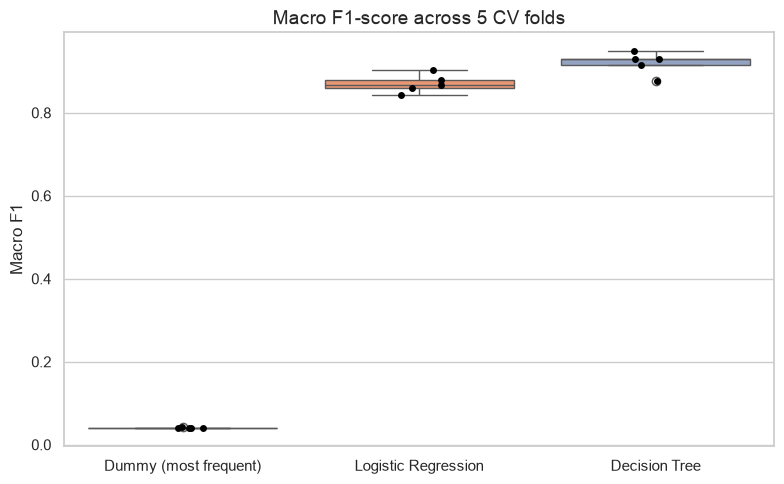

In [23]:
# 6.7 Baseline Comparison (mean ± std across the 5 folds)
summary = pd.DataFrame({
    name: {metric: f"{scores[f'test_{metric}'].mean():.4f} ± {scores[f'test_{metric}'].std():.4f}"
           for metric in scoring}
    for name, scores in cv_results.items()
}).T
summary['train_accuracy'] = [f"{s['train_accuracy'].mean():.4f}" for s in cv_results.values()]
print(summary)

# Per-fold macro F1 for each model
fold_f1 = pd.DataFrame({name: scores['test_f1_macro'] for name, scores in cv_results.items()})
plt.figure(figsize=(8, 5))
sns.boxplot(data=fold_f1, palette='Set2')
sns.stripplot(data=fold_f1, color='black', size=5)
plt.title('Macro F1-score across 5 CV folds', fontsize=14)
plt.ylabel('Macro F1')
plt.tight_layout()
plt.show()

## 6.8 Per-Class Results (out-of-fold predictions)

In [24]:
# 6.8 Per-Class Results
# cross_val_predict gives each training sample a prediction from a model that never saw it.
# The test set stays untouched until the final evaluation (after tuning).
baseline_models = {'Logistic Regression': log_reg_pipeline, 'Decision Tree': tree_pipeline}
oof_predictions = {}

for name, pipeline in baseline_models.items():
    oof_predictions[name] = cross_val_predict(pipeline, X_train_raw, y_train, cv=cv, n_jobs=-1)
    print(f'\n=== {name}: classification report (out-of-fold) ===')
    print(classification_report(y_train, oof_predictions[name], target_names=target_order, digits=3))


=== Logistic Regression: classification report (out-of-fold) ===
                     precision    recall  f1-score   support

Insufficient_Weight      0.893     0.972     0.931       214
      Normal_Weight      0.844     0.698     0.764       225
 Overweight_Level_I      0.749     0.769     0.759       221
Overweight_Level_II      0.764     0.810     0.787       232
     Obesity_Type_I      0.935     0.872     0.902       281
    Obesity_Type_II      0.925     0.987     0.955       237
   Obesity_Type_III      0.989     1.000     0.994       259

           accuracy                          0.875      1669
          macro avg      0.871     0.873     0.870      1669
       weighted avg      0.876     0.875     0.874      1669


=== Decision Tree: classification report (out-of-fold) ===
                     precision    recall  f1-score   support

Insufficient_Weight      0.931     0.939     0.935       214
      Normal_Weight      0.853     0.822     0.837       225
 Overweight_Leve

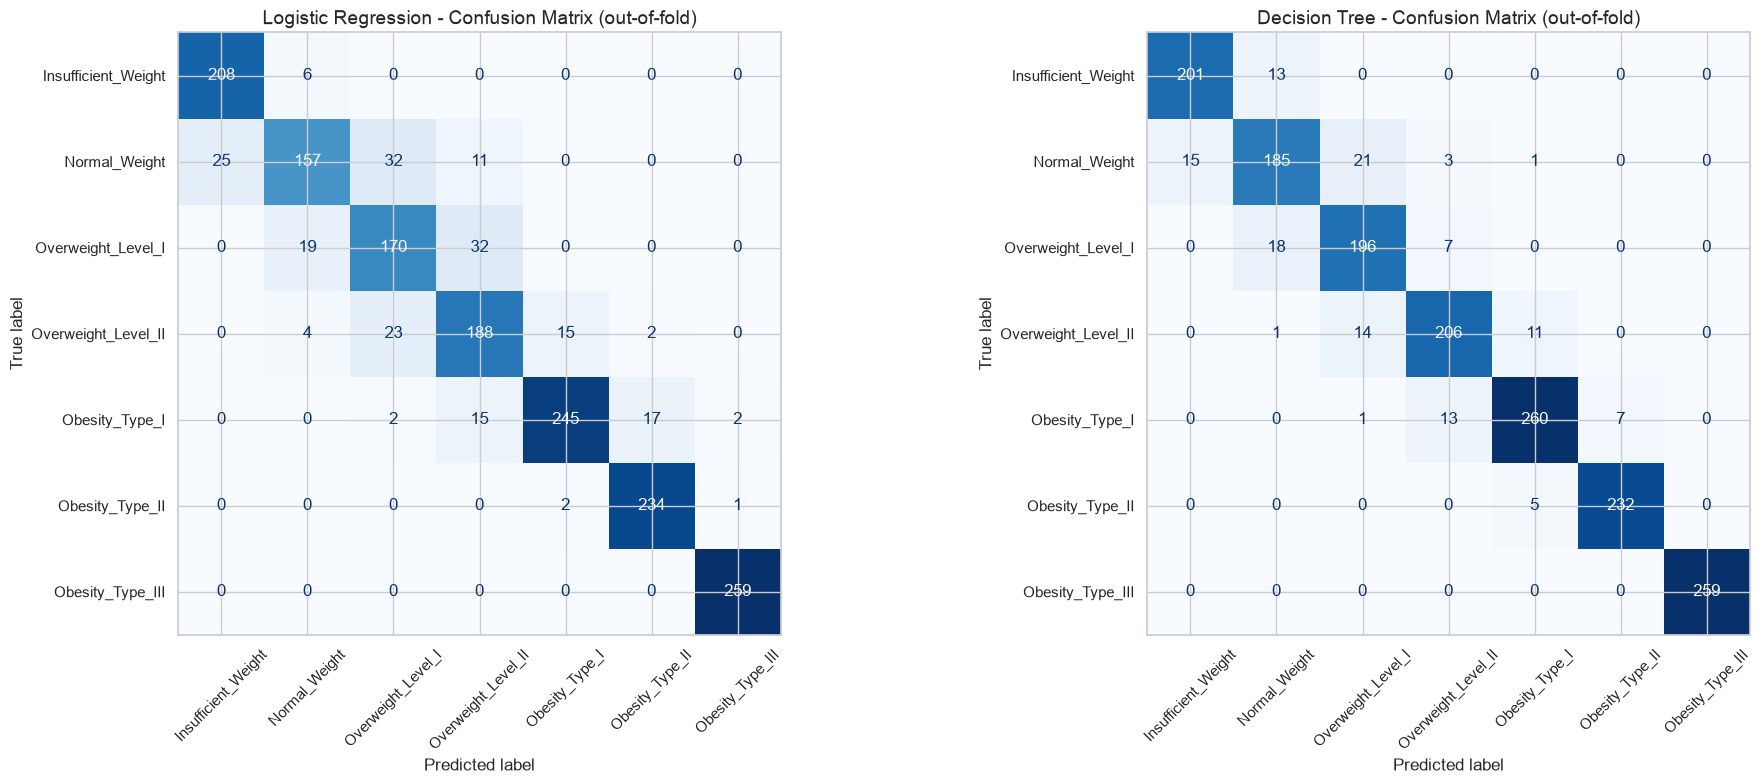

In [25]:
# Confusion matrices (rows = true level, columns = predicted level)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (name, preds) in zip(axes, oof_predictions.items()):
    cm = confusion_matrix(y_train, preds)
    ConfusionMatrixDisplay(cm, display_labels=target_order).plot(
        ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False
    )
    ax.set_title(f'{name} - Confusion Matrix (out-of-fold)', fontsize=14)
plt.tight_layout()
plt.show()

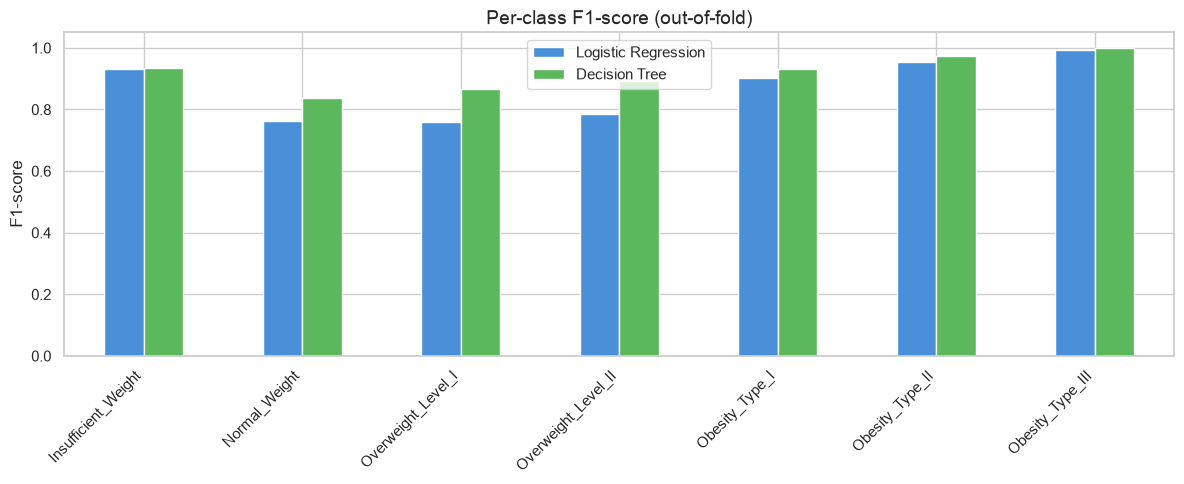

,Logistic Regression,Decision Tree
Insufficient_Weight,0.931,0.935
Normal_Weight,0.764,0.837
Overweight_Level_I,0.759,0.865
Overweight_Level_II,0.787,0.894
Obesity_Type_I,0.902,0.932
Obesity_Type_II,0.955,0.975
Obesity_Type_III,0.994,1.000


In [26]:
# Per-class F1 side by side to see which obesity levels each baseline struggles with
per_class_f1 = pd.DataFrame({
    name: pd.Series(classification_report(y_train, preds, output_dict=True))
          .loc[[str(i) for i in range(len(target_order))]].apply(lambda d: d['f1-score']).values
    for name, preds in oof_predictions.items()
}, index=target_order)

per_class_f1.plot(kind='bar', figsize=(12, 5), color=['#4a90d9', '#5cb85c'])
plt.title('Per-class F1-score (out-of-fold)', fontsize=14)
plt.ylabel('F1-score')
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
per_class_f1.round(3)

## 6.9 Decision Tree Feature Importance

Tree depth: 16  Leaves: 119


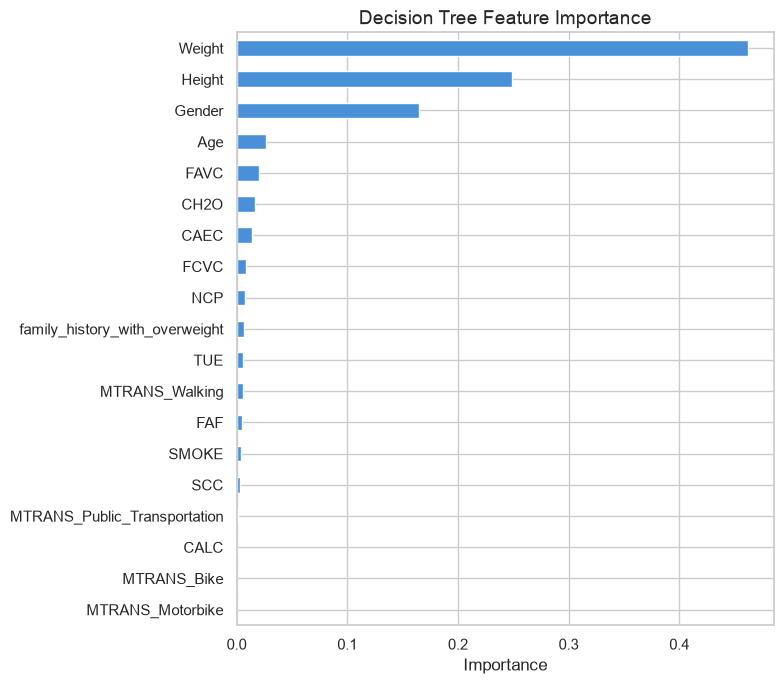

In [27]:
# 6.9 Decision Tree Feature Importance (fit on the full training set)
tree_pipeline.fit(X_train_raw, y_train)
feature_names = [name.split('__', 1)[1] for name in tree_pipeline.named_steps['preprocess'].get_feature_names_out()]
importances = pd.Series(tree_pipeline.named_steps['model'].feature_importances_, index=feature_names).sort_values()

print('Tree depth:', tree_pipeline.named_steps['model'].get_depth(),
      ' Leaves:', tree_pipeline.named_steps['model'].get_n_leaves())

plt.figure(figsize=(8, 7))
importances.plot(kind='barh', color='#4a90d9')
plt.title('Decision Tree Feature Importance', fontsize=14)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()